평가 정확도: 0.4
              precision    recall  f1-score   support

        관계관리       0.50      0.50      0.50         2
      사회적 인식       0.00      0.00      0.00         2
        자기관리       0.50      0.50      0.50         2
        자기인식       0.33      0.50      0.40         2
    책임있는의사결정       1.00      0.50      0.67         2

    accuracy                           0.40        10
   macro avg       0.47      0.40      0.41        10
weighted avg       0.47      0.40      0.41        10



c:\Users\손문\GitHub\qiskit-study\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 44288 (\N{HANGUL SYLLABLE GWAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\손문\GitHub\qiskit-study\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\손문\GitHub\qiskit-study\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\손문\GitHub\qiskit-study\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 49324 (\N{HANGUL SYLLABLE SA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\손문\GitHub\qiskit-study\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 54924 (\N{HANGUL SYLLABLE HOE}) mi

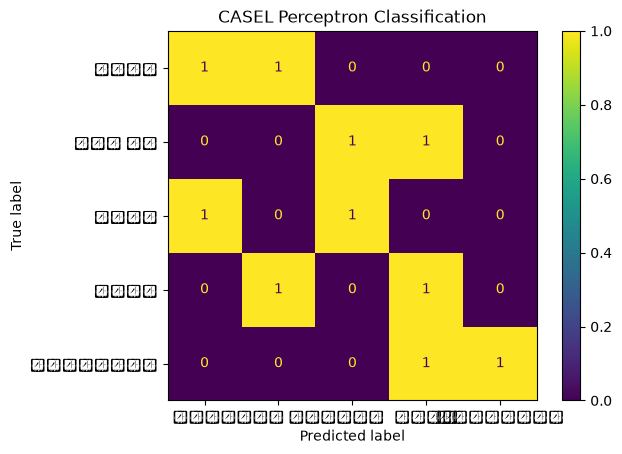

친구가 슬퍼하는 이유를 이해하려고 노력했다. -> 자기인식
화가 났지만 마음을 가라앉히고 기도했다. -> 자기관리
친구에게 사과하고 서로 화해했다. -> 관계관리


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Perceptron
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. CASEL 핵심 역량별 가상 성찰문
examples = {
    "자기인식": [
        "나는 화가 나는 이유를 생각하며 내 감정을 이해했다.",
        "친구의 칭찬을 듣고 나의 장점을 발견했다.",
        "실패했을 때 내가 느끼는 두려움을 알아차렸다.",
        "기도하면서 나의 불안과 걱정을 돌아보았다.",
        "나는 질투심이 생기는 원인을 성찰했다.",
        "나의 강점과 약점을 스스로 이해하게 되었다."
    ],
    "자기관리": [
        "화가 났지만 심호흡하며 마음을 진정시켰다.",
        "어려운 과제에도 포기하지 않고 노력했다.",
        "기도하며 불안한 마음을 조절했다.",
        "시험을 준비하기 위해 시간을 계획했다.",
        "충동적인 행동을 멈추고 인내했다.",
        "스트레스를 조절하기 위해 잠시 휴식했다."
    ],
    "사회적 인식": [
        "친구의 슬픔을 이해하고 공감했다.",
        "다른 문화적 배경을 가진 친구를 존중했다.",
        "어려움을 겪는 이웃의 처지를 생각했다.",
        "상대방의 관점에서 문제를 바라보았다.",
        "소외된 친구의 감정을 헤아렸다.",
        "타인의 아픔에 공감하는 마음을 배웠다."
    ],
    "관계관리": [
        "친구와 대화하며 갈등을 해결했다.",
        "먼저 사과하여 친구와 화해했다.",
        "모둠 활동에서 친구들과 협력했다.",
        "서로 의견이 달랐지만 대화로 조정했다.",
        "친구의 이야기를 경청하며 신뢰를 쌓았다.",
        "공동체에서 서로 돕고 협력했다."
    ],
    "책임있는의사결정": [
        "정직한 선택이 무엇인지 생각하고 행동했다.",
        "내 행동의 결과를 고려하여 결정했다.",
        "공동체에 도움이 되는 선택을 했다.",
        "잘못된 행동을 거절하고 올바르게 판단했다.",
        "친구에게 피해를 주지 않도록 신중하게 결정했다.",
        "정의로운 행동을 선택하기 위해 고민했다."
    ]
}

# 2. 데이터프레임 구성
rows = []
for label, texts in examples.items():
    for text in texts:
        rows.append({"성찰문": text, "CASEL_역량": label})

df = pd.DataFrame(rows)

# 3. 텍스트 수치화
vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(2, 4)
)
X = vectorizer.fit_transform(df["성찰문"])
y = df["CASEL_역량"]

# 4. 학습용 / 평가용 분리
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.33,
    random_state=42,
    stratify=y
)

# 5. 퍼셉트론 학습
model = Perceptron(
    max_iter=1000,
    random_state=42
)
model.fit(X_train, y_train)

# 6. 평가
y_pred = model.predict(X_test)

print("평가 정확도:", accuracy_score(y_test, y_pred))
print(classification_report(
    y_test, y_pred, zero_division=0
))

# 7. 혼동행렬 시각화
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred
)
plt.title("CASEL Perceptron Classification")
plt.show()

# 8. 새로운 성찰문 분류
new_texts = [
    "친구가 슬퍼하는 이유를 이해하려고 노력했다.",
    "화가 났지만 마음을 가라앉히고 기도했다.",
    "친구에게 사과하고 서로 화해했다."
]

new_X = vectorizer.transform(new_texts)
predictions = model.predict(new_X)

for text, label in zip(new_texts, predictions):
    print(f"{text} -> {label}")
